# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Najwa Ayu Ramadhani
- **Email:** ds284b6x1323@student.devacademy.id
- **ID Dicoding:** DS284B6X1323

## Menentukan Pertanyaan Bisnis

### Konteks Bisnis

Olist adalah marketplace yang menghubungkan penjual kecil dengan pembeli di Brasil. Analisis ini ditujukan bagi tim penjualan dan operasional Olist untuk (1) menentukan kategori produk yang diprioritaskan dalam stok dan promosi, serta (2) menyiapkan kapasitas gudang dan logistik berdasarkan pola order bulanan pada tahun 2017.

### Penerapan SMART Question pada Analisis E-Commerce Olist

Dalam proyek ini, metode SMART digunakan untuk memastikan bahwa pertanyaan bisnis yang dirumuskan memiliki tujuan yang jelas, dapat diukur, berorientasi pada tindakan, relevan dengan permasalahan bisnis, dan memiliki batasan waktu.

**Pertanyaan 1: Analisis Revenue Berdasarkan Kategori Produk**

- **Specific:** Berfokus pada lima kategori produk dengan revenue tertinggi dan lima kategori dengan revenue terendah.
- **Measurable:** Mengukur total revenue setiap kategori dan persentase kontribusinya terhadap keseluruhan revenue.
- **Action-Oriented:** Hasil analisis dapat digunakan untuk menentukan kategori produk yang diprioritaskan dalam pengelolaan stok dan promosi.
- **Relevant:** Mengetahui kategori produk yang memberikan kontribusi revenue terbesar dapat membantu perusahaan menentukan strategi penjualan.
- **Time-bound:** Analisis dibatasi pada periode Januari hingga Desember 2017.

**Pertanyaan 2: Analisis Tren Order dan Revenue Bulanan**

- **Specific:** Berfokus pada perubahan jumlah order dan revenue setiap bulan.
- **Measurable:** Mengukur jumlah order dan total revenue bulanan serta mengidentifikasi nilai tertinggi dan terendah.
- **Action-Oriented:** Mengetahui bulan puncak order dan revenue membantu perusahaan menyiapkan stok, gudang, dan logistik sebelum periode tersebut.
- **Relevant:** Memahami pola transaksi bulanan dapat membantu perusahaan menyusun strategi operasional dan penjualan.
- **Time-bound:** Analisis dilakukan selama Januari hingga Desember 2017.

Dengan penerapan SMART tersebut, analisis diharapkan dapat memberikan informasi yang terukur dan membantu memahami performa penjualan E-Commerce Olist selama tahun 2017.

### Pertanyaan Bisnis

Berdasarkan tujuan analisis, terdapat dua pertanyaan bisnis yang akan dijawab:

1. Kategori produk apa saja yang menghasilkan revenue tertinggi dan terendah (5 teratas dan 5 terbawah) sepanjang tahun 2017, serta berapa persentase kontribusinya terhadap total revenue?

2. Bagaimana tren jumlah order dan total revenue bulanan selama Januari–Desember 2017, dan pada bulan apa jumlah order serta revenue mencapai puncaknya?

**Catatan Definisi:**

- Revenue dihitung dari total harga produk (`price`) pada item pesanan yang berstatus selain `canceled` dan `unavailable`. Biaya pengiriman (`freight_value`) tidak dimasukkan.
- Item dari produk yang tidak memiliki kategori tetap dihitung pada analisis tren bulanan (Pertanyaan 2) dan diberi label `uncategorized`. Label ini tidak diikutsertakan dalam peringkat kategori (Pertanyaan 1), tetapi persentase kontribusi tetap dihitung terhadap total revenue seluruh item.
- Periode analisis dibatasi pada Januari sampai Desember 2017 karena hanya tahun 2017 yang memiliki data lengkap selama 12 bulan.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load seluruh tabel

Dataset diunduh dari Kaggle lalu disalin ke folder `data/`. Dataset terdiri dari 9 file CSV.

In [2]:
if not os.path.exists("data"):
    import kagglehub
    path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
    os.makedirs("data", exist_ok=True)
    for f in os.listdir(path):
        shutil.copy(os.path.join(path, f), "data")

print(sorted(os.listdir("data")))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [3]:
customers = pd.read_csv("data/olist_customers_dataset.csv")
geolocation = pd.read_csv("data/olist_geolocation_dataset.csv")
order_items = pd.read_csv("data/olist_order_items_dataset.csv")
payments = pd.read_csv("data/olist_order_payments_dataset.csv")
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")
orders = pd.read_csv("data/olist_orders_dataset.csv")
products = pd.read_csv("data/olist_products_dataset.csv")
sellers = pd.read_csv("data/olist_sellers_dataset.csv")
category_translation = pd.read_csv("data/product_category_name_translation.csv")

tables = {
    "customers": customers, "geolocation": geolocation, "order_items": order_items,
    "payments": payments, "reviews": reviews, "orders": orders,
    "products": products, "sellers": sellers, "category_translation": category_translation,
}
pd.DataFrame({name: df.shape for name, df in tables.items()}, index=["jumlah_baris", "jumlah_kolom"]).T

,jumlah_baris,jumlah_kolom
customers,99441,5
geolocation,1000163,5
order_items,112650,7
payments,103886,5
reviews,99224,7
orders,99441,8
products,32951,9
sellers,3095,4
category_translation,71,2


In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [6]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


**Insight:**
- Dataset terdiri dari 9 tabel yang saling berhubungan melalui beberapa kolom kunci, seperti `customer_id`, `order_id`, dan `product_id`.
- Tabel `orders`, `order_items`, `customers`, dan `products` menjadi tabel utama yang digunakan untuk menganalisis transaksi dan kategori produk.
- Nama kategori produk pada tabel `products` masih menggunakan bahasa Portugis, sehingga perlu digabungkan dengan tabel `category_translation` agar lebih mudah dipahami.
- Tabel `geolocation` memiliki jumlah data yang besar dan mengandung data duplikat, sehingga perlu diperiksa dan dibersihkan sebelum digunakan.

### Assessing Data

#### Identifying invalid data type dan missing value

In [8]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [9]:
for name in ["orders", "products", "reviews"]:
    missing = tables[name].isna().sum()
    print(f"--- {name} ---")
    print(missing[missing > 0], "\n")

--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 

--- reviews ---
review_comment_title      87656
review_comment_message    58247
dtype: int64 



In [10]:
produk_tanpa_kategori = products.loc[products["product_category_name"].isna(), "product_id"]
item_terdampak = order_items[order_items["product_id"].isin(produk_tanpa_kategori)]

print("Produk tanpa kategori       :", len(produk_tanpa_kategori))
print("Item pesanan yang terdampak :", len(item_terdampak), "dari", len(order_items), "item")
print(f"Revenue yang terdampak      : R$ {item_terdampak['price'].sum():,.2f} "
      f"({item_terdampak['price'].sum() / order_items['price'].sum() * 100:.2f}% dari total harga seluruh item)")

Produk tanpa kategori       : 610
Item pesanan yang terdampak : 1603 dari 112650 item
Revenue yang terdampak      : R$ 179,535.28 (1.32% dari total harga seluruh item)


#### Identifying duplicate data

In [11]:
for name, df in tables.items():
    print(f"{name:22s} duplikat: {df.duplicated().sum():>7,} dari {len(df):>9,} baris")

customers              duplikat:       0 dari    99,441 baris
geolocation            duplikat: 261,831 dari 1,000,163 baris
order_items            duplikat:       0 dari   112,650 baris
payments               duplikat:       0 dari   103,886 baris
reviews                duplikat:       0 dari    99,224 baris
orders                 duplikat:       0 dari    99,441 baris
products               duplikat:       0 dari    32,951 baris
sellers                duplikat:       0 dari     3,095 baris
category_translation   duplikat:       0 dari        71 baris


#### Identifying inconsistent value

In [12]:
print("Status order:")
print(orders["order_status"].value_counts(), "\n")

orders_date = pd.to_datetime(orders["order_purchase_timestamp"])
print("Rentang tanggal order:", orders_date.min(), "s.d.", orders_date.max(), "\n")
print("Jumlah order per bulan:")
print(orders_date.dt.to_period("M").value_counts().sort_index().to_string())

Status order:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Rentang tanggal order: 2016-09-04 21:15:19 s.d. 2018-10-17 17:30:18 

Jumlah order per bulan:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [13]:
no_translation = set(products["product_category_name"].dropna()) - set(category_translation["product_category_name"])
print("Kategori tanpa terjemahan:", no_translation)

print("\nJumlah customer_id        :", customers["customer_id"].nunique())
print("Jumlah customer_unique_id :", customers["customer_unique_id"].nunique())

Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}

Jumlah customer_id        : 99441
Jumlah customer_unique_id : 96096


**Steps to Take:**
- **Missing value (tanggal pada tabel `orders`):** kolom `order_approved_at`, `order_delivered_carrier_date`, dan `order_delivered_customer_date` memiliki nilai kosong. Kolom-kolom ini tidak digunakan untuk menjawab pertanyaan bisnis, sehingga nilai kosongnya dibiarkan.
- **Missing value (kategori produk):** 610 produk tidak memiliki kategori. Produk tidak dihapus karena Pertanyaan 2 tidak membutuhkan kategori, dan penghapusan akan mengurangi jumlah order serta revenue bulanan. Produk tersebut diberi label `uncategorized` dan dikeluarkan dari peringkat kategori pada Pertanyaan 1.
- **Duplicate data:** tabel `geolocation` memiliki 261.831 baris duplikat yang dihapus dengan `drop_duplicates()`.
- **Invalid data type:** lima kolom tanggal pada tabel `orders` masih bertipe `object` dan diubah menjadi `datetime`.
- **Filtering status pesanan:** pesanan berstatus `canceled` dan `unavailable` tidak dihitung dalam revenue karena tidak merepresentasikan pesanan yang berhasil diproses.
- **Incomplete reference data (terjemahan kategori):** kategori `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos` belum ada di tabel terjemahan dan ditambahkan secara manual.
- **Identitas pelanggan:** jumlah pelanggan dihitung dengan `customer_unique_id`, bukan `customer_id`, karena satu pelanggan dapat memiliki beberapa `customer_id`.

**Insight:**
- Dataset memiliki 99.441 pesanan dengan rentang waktu dari 4 September 2016 sampai 17 Oktober 2018.
- Data tahun 2016 hanya mencakup 329 pesanan. Data tahun 2018 tercatat sampai Oktober, tetapi September-Oktober 2018 hanya berisi 20 pesanan sehingga data yang terisi penuh hanya sampai Agustus. Tahun 2017 merupakan satu-satunya tahun dengan data lengkap selama 12 bulan.
- Sebagian besar pesanan memiliki status `delivered`, yaitu sebanyak 96.478 pesanan dari total 99.441 pesanan.
- Ditemukan 610 produk tanpa kategori dan 261.831 baris duplikat pada tabel `geolocation`. Kedua permasalahan tersebut perlu ditangani pada tahap data cleaning.
- Produk tanpa kategori memengaruhi 1.603 dari 112.650 item pesanan, dengan total harga R$ 179.535,28 (1,32% dari total harga seluruh item). Karena pengaruhnya tidak kecil terhadap tren bulanan, produk tersebut dipertahankan dengan label `uncategorized`, bukan dihapus.

### Cleaning Data

#### Fixing invalid data type

Pada tahap Assessing, kelima kolom tanggal pada tabel `orders` terdeteksi bertipe `object`, yaitu `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`. Seluruhnya diubah menjadi tipe `datetime` agar dapat digunakan untuk memfilter dan menganalisis data berdasarkan waktu.

In [14]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)
orders[date_cols].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing duplicate data

Pemeriksaan sebelumnya menemukan 261.831 baris duplikat pada tabel `geolocation`. Data duplikat perlu dihapus agar tidak terjadi pengulangan informasi yang dapat mengganggu proses analisis.

Penghapusan dilakukan menggunakan fungsi `drop_duplicates()`, sehingga setiap baris yang identik hanya disimpan satu kali.

In [15]:
geolocation = geolocation.drop_duplicates()
print("Duplikat tersisa:", geolocation.duplicated().sum(), "| jumlah baris:", len(geolocation))

Duplikat tersisa: 0 | jumlah baris: 738332


#### Filtering pesanan berdasarkan status

Pada tabel `orders`, terdapat beberapa status pesanan. Untuk analisis revenue, pesanan dengan status `canceled` dan `unavailable` tidak disertakan karena kedua status tersebut tidak merepresentasikan pesanan yang berhasil diproses.

Data dengan kedua status tersebut dikeluarkan menggunakan kondisi filter pada kolom `order_status`.

In [16]:
orders_clean = orders[~orders["order_status"].isin(["canceled", "unavailable"])]
print("Order sebelum:", len(orders), "| sesudah:", len(orders_clean))

Order sebelum: 99441 | sesudah: 98207


#### Menangani missing value dan incomplete reference data (kategori produk)

Pada tabel `products`, ditemukan 610 produk yang tidak memiliki nilai pada kolom `product_category_name`. Produk tersebut tidak dihapus karena kategori tidak dibutuhkan untuk menjawab Pertanyaan 2 (tren bulanan), dan penghapusan akan mengurangi jumlah order serta revenue bulanan. Produk tersebut diberi label `uncategorized`, lalu dikeluarkan dari peringkat kategori pada Pertanyaan 1.

Selain itu, terdapat dua kategori produk yang belum tersedia pada tabel terjemahan, yaitu `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`. Kedua kategori tersebut ditambahkan secara manual ke tabel terjemahan.

In [17]:
# Muat ulang tabel agar sel ini aman dijalankan berulang
products = pd.read_csv("data/olist_products_dataset.csv")
category_translation = pd.read_csv("data/product_category_name_translation.csv")

extra_translation = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers"],
})
category_translation = pd.concat([category_translation, extra_translation], ignore_index=True)

products = products.merge(category_translation, on="product_category_name", how="left")

# Pastikan tidak ada kategori berisi yang belum terjemahannya
tanpa_terjemahan = products["product_category_name"].notna() & products["product_category_name_english"].isna()
print("Kategori yang masih tanpa terjemahan:", tanpa_terjemahan.sum())

# Produk tanpa kategori diberi label, bukan dihapus
products["product_category_name_english"] = products["product_category_name_english"].fillna("uncategorized")
print("Produk berlabel 'uncategorized':", (products["product_category_name_english"] == "uncategorized").sum())

Kategori yang masih tanpa terjemahan: 0
Produk berlabel 'uncategorized': 610


#### Menggabungkan tabel menjadi `all_df`

Setelah proses cleaning selesai, beberapa tabel digabungkan untuk membentuk satu dataset utama bernama `all_df`. Produk tanpa kategori tetap dipertahankan dalam all_df dengan label uncategorized.

Penggabungan dilakukan menggunakan kolom kunci:
- `customer_id` untuk menghubungkan tabel `orders` dan `customers`.
- `order_id` untuk menghubungkan tabel transaksi dengan `order_items`.
- `product_id` untuk menghubungkan detail pesanan dengan kategori produk pada tabel `products`.

Penggabungan menggunakan metode `inner join` agar hanya data yang memiliki pasangan pada tabel terkait yang dimasukkan ke dataset akhir.

Selanjutnya, kolom `order_purchase_timestamp` diubah namanya menjadi `order_date`, kolom `price` menjadi `revenue`, dan nama kategori produk diterjemahkan ke dalam kolom `category`.

Analisis kemudian difokuskan pada transaksi tahun 2017 karena tahun tersebut memiliki data lengkap selama 12 bulan.

In [18]:
all_df = (
    orders_clean
    .merge(customers, on="customer_id", how="inner")
    .merge(order_items, on="order_id", how="inner")
    .merge(products[["product_id", "product_category_name_english"]], on="product_id", how="inner")
)

all_df = all_df.rename(columns={
    "order_purchase_timestamp": "order_date",
    "price": "revenue",
    "product_category_name_english": "category",
})

# Fokus tahun 2017
all_df = all_df[all_df["order_date"].dt.year == 2017].reset_index(drop=True)

print("Ukuran all_df:", all_df.shape)
all_df.head()

Ukuran all_df: (50617, 19)


,order_id,customer_id,order_status,order_date,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,revenue,freight_value,category
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares
1,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop
2,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01,80bb27c7c16e8f973207a5086ab329e2,86320,congonhinhas,PR,1,060cb19345d90064d1015407193c233d,8581055ce74af1daba164fdbd55a40de,2017-07-13 22:10:13,147.90,27.36,auto
3,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,NaT,2017-05-09,36edbb3fb164b1f16485364b6fb04c73,98900,santa rosa,RS,1,a1804276d9941ac0733cfd409f5206eb,dc8798cbf453b7e0f98745e396cc5616,2017-04-19 13:25:17,49.90,16.05,uncategorized
4,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,932afa1e708222e5821dac9cd5db4cae,26525,nilopolis,RJ,1,4520766ec412348b8d4caa5e8a18c464,16090f2ca825584b5a147ab24aa30c86,2017-05-22 13:22:11,59.99,15.17,auto


In [19]:
all_df.isna().sum()[all_df.isna().sum() > 0]

,0
order_approved_at,15
order_delivered_carrier_date,497
order_delivered_customer_date,1063


In [20]:
os.makedirs("dashboard", exist_ok=True)
main_columns = ["order_id", "customer_unique_id", "order_date", "category", "revenue"]
all_df[main_columns].to_csv("dashboard/main_data.csv", index=False)

**Insight:**
- Setelah cleaning dan penggabungan, `all_df` berisi 50.617 baris item pesanan dari 44.375 order unik tahun 2017.
- Nilai kosong yang tersisa hanya pada kolom tanggal di tabel `orders`, yaitu `order_approved_at` (15 baris), tanggal pengiriman ke kurir (497 baris), dan tanggal pesanan diterima pelanggan (1.063 baris). Kolom-kolom ini tidak digunakan dalam analisis.
- Tabel `payments`, `reviews`, dan `sellers` tidak digunakan pada dua pertanyaan bisnis ini.

## Exploratory Data Analysis (EDA)

Pada tahap ini, dilakukan eksplorasi awal terhadap dataset `all_df` untuk memahami karakteristik data setelah proses cleaning dan penggabungan tabel.

Eksplorasi dilakukan menggunakan fungsi `describe()` untuk melihat ringkasan statistik, jumlah data, serta variasi nilai pada setiap kolom. Selanjutnya, dihitung jumlah order unik, pelanggan unik, kategori produk, dan total revenue selama tahun 2017.

In [21]:
all_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,50617,44375,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,50617,44375,fc3d1daec319d62d49bfb5e1f83123e9,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_status,50617,5,delivered,49556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,50617,NaN,NaN,NaN,2017-08-16 03:06:22.651777280,2017-01-05 11:56:06,2017-06-01 10:35:51,2017-08-30 14:24:18,2017-11-13 21:32:02,2017-12-31 23:29:31,NaN
order_approved_at,50602,NaN,NaN,NaN,2017-08-16 14:44:21.540077312,2017-01-05 12:10:17,2017-06-01 16:25:29.500000,2017-08-31 00:00:07.500000,2017-11-14 08:16:24.750000128,2018-01-04 23:17:35,NaN
order_delivered_carrier_date,50120,NaN,NaN,NaN,2017-08-19 20:42:52.089585152,2017-01-06 12:43:41,2017-06-05 14:05:55.750000128,2017-09-01 20:07:41.500000,2017-11-17 16:02:54.750000128,2018-03-20 15:44:40,NaN
order_delivered_customer_date,49554,NaN,NaN,NaN,2017-08-29 14:28:51.693788416,2017-01-11 13:14:05,2017-06-13 17:56:08.500000,2017-09-12 17:14:52.500000,2017-11-25 18:37:03.249999872,2018-05-21 18:22:18,NaN
order_estimated_delivery_date,50617,NaN,NaN,NaN,2017-09-09 21:00:51.421459200,2017-02-01 00:00:00,2017-06-27 00:00:00,2017-09-21 00:00:00,2017-12-06 00:00:00,2018-04-06 00:00:00,NaN
customer_unique_id,50617,43030,4546caea018ad8c692964e3382debd19,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,50617.0,NaN,NaN,NaN,36304.804532,1004.0,12244.0,26165.0,60712.0,99990.0,29849.220569


In [22]:
print("Jumlah order unik       :", all_df["order_id"].nunique())
print("Jumlah pelanggan unik   :", all_df["customer_unique_id"].nunique())
print("Jumlah kategori produk  :", all_df["category"].nunique())
print(f"Total revenue 2017      : R$ {all_df['revenue'].sum():,.2f}")

Jumlah order unik       : 44375
Jumlah pelanggan unik   : 43030
Jumlah kategori produk  : 73
Total revenue 2017      : R$ 6,108,492.27


Analisis ini dilakukan untuk mengetahui kategori produk yang memberikan kontribusi revenue terbesar dan terkecil selama tahun 2017.

Data dikelompokkan berdasarkan kategori produk, kemudian dihitung total revenue dan jumlah order unik pada setiap kategori. Persentase kontribusi revenue juga dihitung untuk mengetahui seberapa besar kontribusi masing-masing kategori terhadap total revenue.

In [23]:
category_df = (
    all_df.groupby("category")
    .agg(revenue=("revenue", "sum"), order_count=("order_id", "nunique"))
    .reset_index()
)
total_revenue = category_df["revenue"].sum()
category_df["revenue_pct"] = category_df["revenue"] / total_revenue * 100
category_df["revenue_per_order"] = category_df["revenue"] / category_df["order_count"]

uncategorized_pct = category_df.loc[category_df["category"] == "uncategorized", "revenue_pct"].sum()

category_df = (
    category_df[category_df["category"] != "uncategorized"]
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)

print("Top 5 kategori:")
display(category_df.head(5))
print("Bottom 5 kategori:")
display(category_df.tail(5))
print(f"Kontribusi 5 kategori teratas   : {category_df.head(5)['revenue_pct'].sum():.1f}% dari total revenue")
print(f"Kontribusi produk uncategorized : {uncategorized_pct:.1f}% dari total revenue")

Top 5 kategori:


,category,revenue,order_count,revenue_pct,revenue_per_order
0,bed_bath_table,497970.94,4496,8.152109,110.758661
1,watches_gifts,486519.02,2114,7.964633,230.141447
2,health_beauty,481142.73,3382,7.876620,142.265739
3,sports_leisure,447546.59,3621,7.326629,123.597512
4,computers_accessories,400490.61,2606,6.556292,153.680203


Bottom 5 kategori:


,category,revenue,order_count,revenue_pct,revenue_per_order
67,fashion_childrens_clothes,399.88,5,0.006546,79.9760
68,security_and_services,283.29,2,0.004638,141.6450
69,flowers,270.50,8,0.004428,33.8125
70,arts_and_craftmanship,151.89,2,0.002487,75.9450
71,diapers_and_hygiene,76.00,1,0.001244,76.0000


Kontribusi 5 kategori teratas   : 37.9% dari total revenue
Kontribusi produk uncategorized : 1.7% dari total revenue


Analisis tren bulanan dilakukan untuk melihat perubahan jumlah order dan revenue dari Januari hingga Desember 2017.

Data dikelompokkan berdasarkan bulan pembelian. Jumlah order dihitung menggunakan jumlah `order_id` unik, sedangkan revenue dihitung dari total harga produk. Selain itu, dihitung persentase perubahan dari bulan sebelumnya (Month-over-Month) untuk melihat kenaikan atau penurunan setiap bulan.

In [24]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

monthly_df = (
    all_df.groupby(all_df["order_date"].dt.to_period("M"))
    .agg(order_count=("order_id", "nunique"), revenue=("revenue", "sum"))
    .reset_index()
    .rename(columns={"order_date": "month"})
)
monthly_df["month_label"] = monthly_df["month"].dt.month.map(lambda m: nama_bulan[m - 1])
monthly_df["order_mom_pct"] = monthly_df["order_count"].pct_change() * 100
monthly_df["revenue_mom_pct"] = monthly_df["revenue"].pct_change() * 100
monthly_df.round({"order_mom_pct": 1, "revenue": 1, "revenue_mom_pct": 1})

,month,order_count,revenue,month_label,order_mom_pct,revenue_mom_pct
0,2017-01,787,120098.3,Jan,NaN,NaN
1,2017-02,1718,244959.4,Feb,118.3,104.0
2,2017-03,2617,368341.3,Mar,52.3,50.4
3,2017-04,2377,353843.0,Apr,-9.2,-3.9
4,2017-05,3640,503159.2,Mei,53.1,42.2
5,2017-06,3205,429916.6,Jun,-12.0,-14.6
6,2017-07,3946,492287.3,Jul,23.1,14.5
7,2017-08,4272,568245.8,Agu,8.3,15.4
8,2017-09,4227,621415.9,Sep,-1.1,9.4
9,2017-10,4547,660179.6,Okt,7.6,6.2


**Insight:**
- Total revenue 2017 sekitar R$ 6,1 juta (R$ 6.108.492,27) dari 73 label kategori, yaitu 72 kategori produk ditambah label `uncategorized`.
- Revenue terkonsentrasi: 5 kategori teratas menyumbang sekitar 37,9% dari total revenue, sedangkan produk `uncategorized` menyumbang sekitar 1,7%.
- Kategori terbawah hanya menghasilkan puluhan hingga ratusan Real dari sedikit order (misalnya `diapers_and_hygiene` hanya R$ 76 dari 1 order).
- Revenue per order berbeda jauh antar kategori teratas: `watches_gifts` sekitar R$ 230 per order, sedangkan `bed_bath_table` sekitar R$ 111 per order.
- Order dan revenue bulanan cenderung naik sepanjang tahun, dengan lonjakan terbesar pada November dan penurunan pada Desember.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menghasilkan revenue tertinggi dan terendah sepanjang tahun 2017, dan berapa persen kontribusinya?

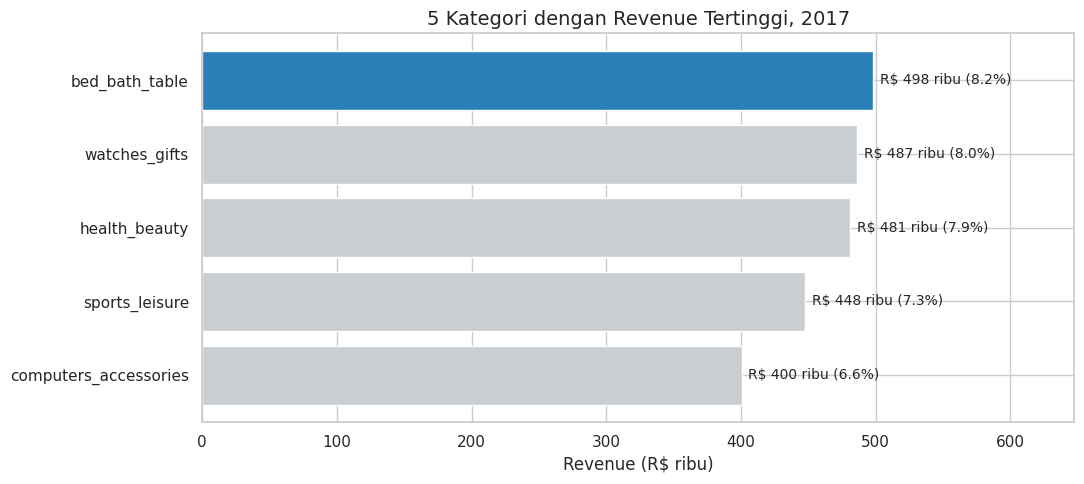

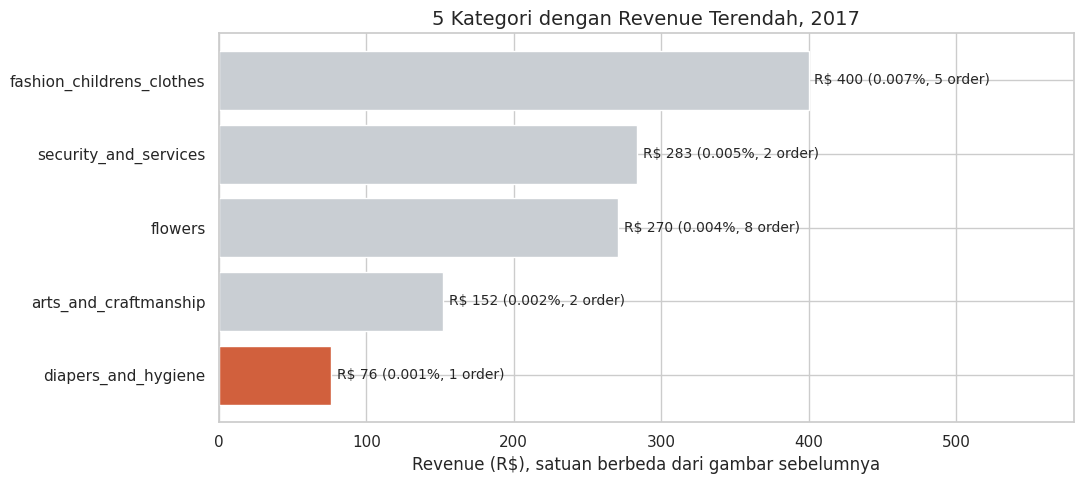

In [25]:
HIGHLIGHT = "#2A7FB8"
MUTED = "#C9CED3"
WARNING = "#D1603D"

top5 = category_df.head(5).iloc[::-1]
bottom5 = category_df.tail(5).iloc[::-1]

# Gambar 1: 5 kategori dengan revenue tertinggi (satuan: R$ ribu)
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top5["category"], top5["revenue"] / 1000, color=[MUTED] * 4 + [HIGHLIGHT])
for i, (rev, pct) in enumerate(zip(top5["revenue"], top5["revenue_pct"])):
    ax.text(rev / 1000 + top5["revenue"].max() / 1000 * 0.01, i,
            f"R$ {rev/1000:,.0f} ribu ({pct:.1f}%)", va="center", fontsize=10)
ax.set_xlim(0, top5["revenue"].max() / 1000 * 1.3)
ax.set_title("5 Kategori dengan Revenue Tertinggi, 2017", fontsize=14)
ax.set_xlabel("Revenue (R$ ribu)")
ax.set_ylabel(None)
plt.tight_layout()
plt.show()

# Gambar 2: 5 kategori dengan revenue terendah (satuan: R$, bukan ribu)
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(bottom5["category"], bottom5["revenue"], color=[WARNING] + [MUTED] * 4)
for i, (rev, pct, n) in enumerate(zip(bottom5["revenue"], bottom5["revenue_pct"], bottom5["order_count"])):
    ax.text(rev + bottom5["revenue"].max() * 0.01, i,
            f"R$ {rev:,.0f} ({pct:.3f}%, {n} order)", va="center", fontsize=10)
ax.set_xlim(0, bottom5["revenue"].max() * 1.45)
ax.set_title("5 Kategori dengan Revenue Terendah, 2017", fontsize=14)
ax.set_xlabel("Revenue (R$), satuan berbeda dari gambar sebelumnya")
ax.set_ylabel(None)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana tren jumlah order dan total revenue bulanan selama 2017, dan pada bulan apa puncaknya?

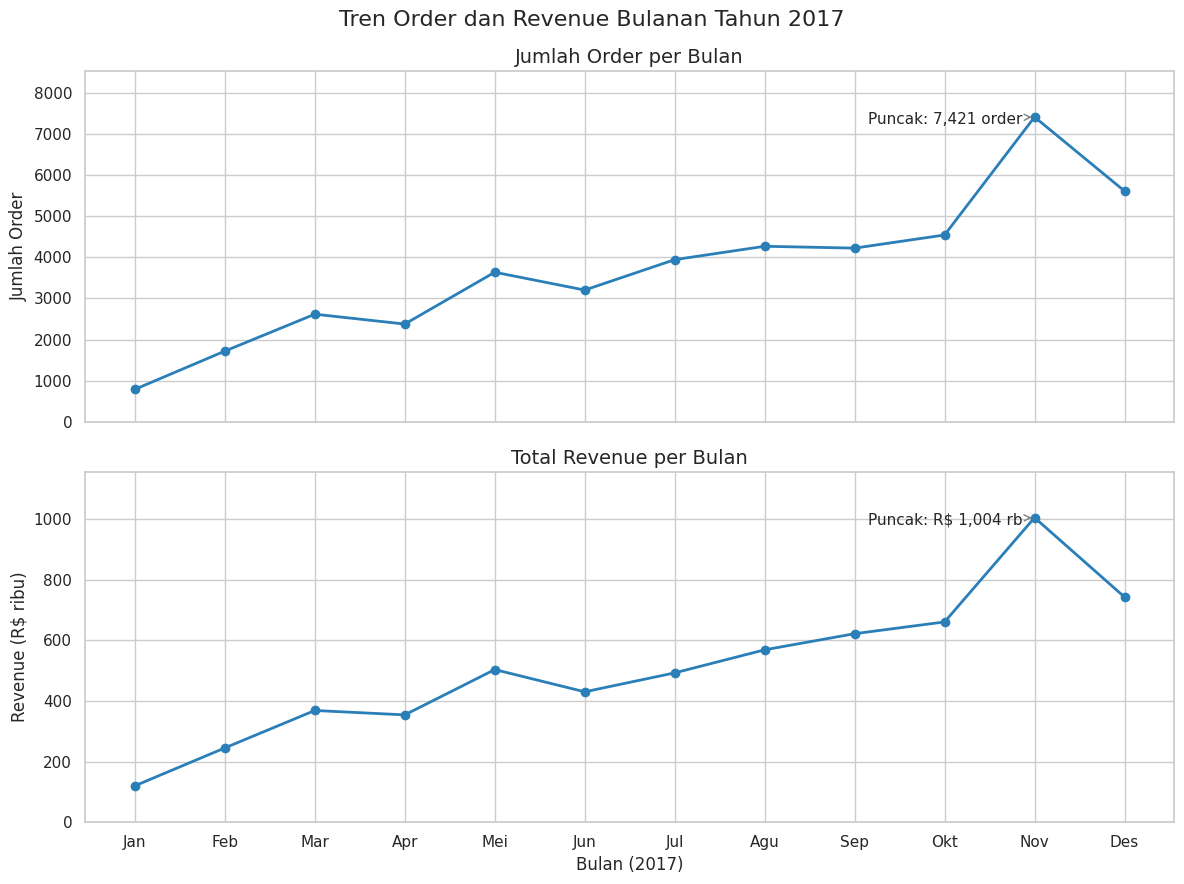

In [26]:
# Menentukan puncak jumlah order dan revenue secara terpisah
peak_order = monthly_df.loc[monthly_df["order_count"].idxmax()]
peak_revenue = monthly_df.loc[monthly_df["revenue"].idxmax()]

fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(12, 9), sharex=True)

# Grafik jumlah order
ax[0].plot(
    monthly_df["month_label"],
    monthly_df["order_count"],
    marker="o",
    linewidth=2,
    color=HIGHLIGHT
)
ax[0].set_title("Jumlah Order per Bulan", fontsize=14)
ax[0].set_ylabel("Jumlah Order")
ax[0].set_ylim(0, monthly_df["order_count"].max() * 1.15)

ax[0].annotate(
    f"Puncak: {int(peak_order['order_count']):,} order",
    xy=(peak_order["month_label"], peak_order["order_count"]),
    xytext=(-120, -5),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="gray"),
    fontsize=11
)

# Grafik revenue
ax[1].plot(
    monthly_df["month_label"],
    monthly_df["revenue"] / 1000,
    marker="o",
    linewidth=2,
    color=HIGHLIGHT
)
ax[1].set_title("Total Revenue per Bulan", fontsize=14)
ax[1].set_ylabel("Revenue (R$ ribu)")
ax[1].set_xlabel("Bulan (2017)")
ax[1].set_ylim(0, monthly_df["revenue"].max() / 1000 * 1.15)

ax[1].annotate(
    f"Puncak: R$ {peak_revenue['revenue']/1000:,.0f} rb",
    xy=(
        peak_revenue["month_label"],
        peak_revenue["revenue"] / 1000
    ),
    xytext=(-120, -5),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="gray"),
    fontsize=11
)

plt.suptitle("Tren Order dan Revenue Bulanan Tahun 2017", fontsize=16)
plt.tight_layout()
plt.show()

In [27]:
monthly_df[["month_label", "order_count", "order_mom_pct", "revenue", "revenue_mom_pct"]].round(
    {"order_mom_pct": 1, "revenue": 1, "revenue_mom_pct": 1}
)

,month_label,order_count,order_mom_pct,revenue,revenue_mom_pct
0,Jan,787,NaN,120098.3,NaN
1,Feb,1718,118.3,244959.4,104.0
2,Mar,2617,52.3,368341.3,50.4
3,Apr,2377,-9.2,353843.0,-3.9
4,Mei,3640,53.1,503159.2,42.2
5,Jun,3205,-12.0,429916.6,-14.6
6,Jul,3946,23.1,492287.3,14.5
7,Agu,4272,8.3,568245.8,15.4
8,Sep,4227,-1.1,621415.9,9.4
9,Okt,4547,7.6,660179.6,6.2


**Insight Pertanyaan 1:**
- Lima kategori teratas adalah `bed_bath_table` (8,2%), `watches_gifts` (8,0%), `health_beauty` (7,9%), `sports_leisure` (7,3%), dan `computers_accessories` (6,6%), totalnya sekitar 37,9% dari total revenue.
- Kontribusi antar kategori teratas relatif merata, tidak ada satu kategori yang mendominasi.
- Karakternya berbeda: `bed_bath_table` unggul karena volume order (4.496 order, sekitar R$ 111 per order), sedangkan `watches_gifts` unggul karena nilai per order (2.114 order, sekitar R$ 230 per order).
- Lima kategori terbawah masing-masing menyumbang kurang dari 0,01% revenue dan hanya diwakili 1 sampai 8 order, sehingga hasilnya perlu dibaca dengan hati-hati.

**Insight Pertanyaan 2:**
- Order naik dari 787 (Januari) menjadi 7.421 (November), dan revenue naik dari sekitar R$ 120 ribu menjadi sekitar R$ 1,0 juta (R$ 1.003.862).
- **November adalah puncaknya**: order naik 63,2% dan revenue naik 52,1% dibanding Oktober.
- Desember turun (order -24,3%, revenue -26,1%), tetapi masih di atas level Oktober.

## Analisis Lanjutan (Opsional)

### Analisis RFM (Recency, Frequency, Monetary)

Analisis RFM digunakan untuk memahami perilaku pelanggan berdasarkan tiga aspek, yaitu:

- **Recency:** jarak waktu sejak transaksi terakhir pelanggan.
- **Frequency:** jumlah transaksi yang dilakukan pelanggan.
- **Monetary:** total nilai pembelian pelanggan.

Analisis ini menggunakan data transaksi tahun 2017 agar konsisten dengan periode analisis utama. Setiap pelanggan diberi skor Recency, Frequency, dan Monetary (1-5), lalu dikelompokkan ke dalam segmen berdasarkan skor Recency dan Frequency. Monetary digunakan untuk membandingkan nilai belanja rata-rata antar segmen.

Perhitungan Frequency menggunakan jumlah `order_id` unik, bukan jumlah baris transaksi, karena satu pesanan dapat berisi lebih dari satu produk.


**Keterbatasan:** analisis hanya memakai transaksi tahun 2017 dengan tanggal acuan 1 Januari 2018. Pelanggan yang tampak "At Risk" sebagian disebabkan oleh batas periode ini, karena pembelian mereka pada tahun 2018 tidak ikut dihitung. Selain itu, mayoritas pelanggan hanya bertransaksi sekali, sehingga skor Frequency hampir seragam dan segmen terutama dibedakan oleh Recency.

In [28]:
# Menentukan tanggal acuan untuk menghitung Recency
snapshot_date = pd.Timestamp("2018-01-01")

# Menghitung nilai RFM untuk setiap pelanggan
rfm_df = (
    all_df.groupby("customer_unique_id")
    .agg(
        recency=("order_date", lambda x: (snapshot_date - x.max()).days),
        frequency=("order_id", "nunique"),
        monetary=("revenue", "sum")
    )
    .reset_index()
)

# Membuat skor Recency
# Semakin baru transaksi terakhir, semakin tinggi skornya
rfm_df["R_score"] = pd.qcut(
    rfm_df["recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Membuat skor Frequency berdasarkan jumlah transaksi (skor maksimal 5)
rfm_df["F_score"] = rfm_df["frequency"].clip(upper=5)

# Membuat skor Monetary
rfm_df["M_score"] = pd.qcut(
    rfm_df["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Menggabungkan skor RFM
rfm_df["RFM_score"] = (
    rfm_df["R_score"].astype(str)
    + rfm_df["F_score"].astype(str)
    + rfm_df["M_score"].astype(str)
)

# Mengelompokkan pelanggan berdasarkan Recency dan Frequency
def segment_customer(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Loyal Customers"
    elif row["R_score"] >= 4:
        return "Recent Customers"
    elif row["R_score"] <= 2 and row["F_score"] <= 2:
        return "At Risk"
    else:
        return "Regular Customers"

rfm_df["segment"] = rfm_df.apply(segment_customer, axis=1)

# Menampilkan hasil RFM
print("Jumlah pelanggan:", len(rfm_df))

display(rfm_df.head())

print("\nJumlah pelanggan per segmen:")
display(
    rfm_df["segment"]
    .value_counts()
    .rename_axis("segment")
    .reset_index(name="customer_count")
)

print("\nPersentase pelanggan per segmen:")
display(
    (rfm_df["segment"].value_counts(normalize=True) * 100)
    .round(2)
    .rename_axis("segment")
    .reset_index(name="percentage")
)

Jumlah pelanggan: 43030


,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segment
0,0000f46a3911fa3c0805444483337064,296,1,69.00,1,1,3,113,At Risk
1,0000f6ccb0745a6a4b88665a16c9f078,80,1,25.99,4,1,1,411,Recent Customers
2,0004aac84e0df4da2b147fca70cf8255,47,1,180.00,4,1,5,415,Recent Customers
3,0005e1862207bf6ccc02e4228effd9a0,302,1,135.00,1,1,4,114,At Risk
4,0006fdc98a402fceb4eb0ee528f6a8d4,166,1,13.90,2,1,1,211,At Risk



Jumlah pelanggan per segmen:


,segment,customer_count
0,Recent Customers,17200
1,At Risk,17184
2,Regular Customers,8634
3,Loyal Customers,12



Persentase pelanggan per segmen:


,segment,percentage
0,Recent Customers,39.97
1,At Risk,39.93
2,Regular Customers,20.07
3,Loyal Customers,0.03


In [29]:
print("Distribusi R_score:")
print(rfm_df["R_score"].value_counts().sort_index())

print("\nDistribusi F_score:")
print(rfm_df["F_score"].value_counts().sort_index())

print("\nDistribusi M_score:")
print(rfm_df["M_score"].value_counts().sort_index())

print("\nRata-rata RFM setiap segmen:")
display(
    rfm_df.groupby("segment")[
        ["recency", "frequency", "monetary"]
    ].mean().round(2)
)
pembeli_sekali = (rfm_df["frequency"] == 1).sum()
print(f"Pelanggan yang hanya membeli sekali: {pembeli_sekali:,} dari {len(rfm_df):,} "
      f"({pembeli_sekali / len(rfm_df) * 100:.1f}%)")

Distribusi R_score:
R_score
1    8606
2    8606
3    8606
4    8606
5    8606
Name: count, dtype: int64

Distribusi F_score:
F_score
1    41810
2     1125
3       76
4       13
5        6
Name: count, dtype: int64

Distribusi M_score:
M_score
1    8606
2    8606
3    8606
4    8606
5    8606
Name: count, dtype: int64

Rata-rata RFM setiap segmen:


,recency,frequency,monetary
segment,,,
At Risk,238.15,1.02,141.14
Loyal Customers,38.50,4.75,487.97
Recent Customers,42.77,1.03,141.06
Regular Customers,123.48,1.04,144.90


Pelanggan yang hanya membeli sekali: 41,810 dari 43,030 (97.2%)


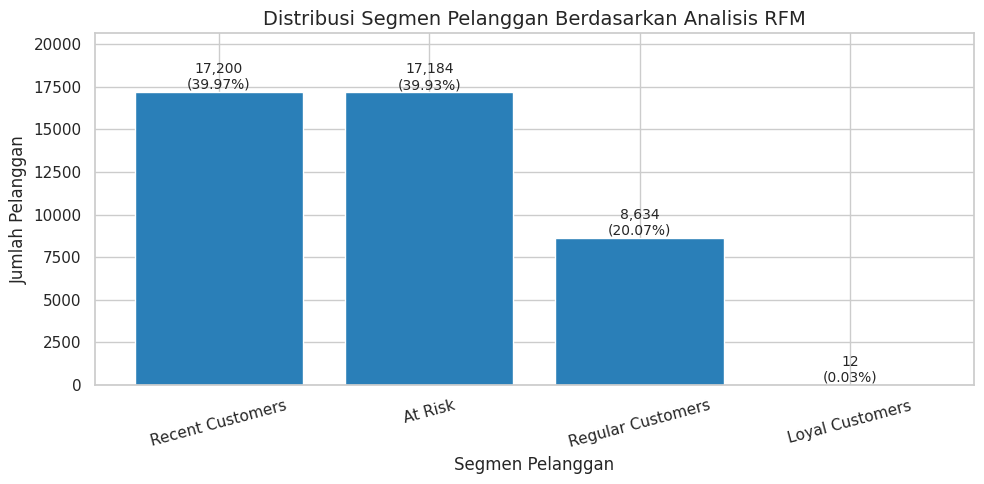

In [30]:
# Menghitung jumlah pelanggan pada setiap segmen
segment_counts = (
    rfm_df["segment"]
    .value_counts()
    .reindex(
        ["Recent Customers", "At Risk", "Regular Customers", "Loyal Customers"],
        fill_value=0
    )
)

# Membuat grafik segmentasi pelanggan
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    segment_counts.index,
    segment_counts.values,
    color=HIGHLIGHT
)

ax.set_title("Distribusi Segmen Pelanggan Berdasarkan Analisis RFM", fontsize=14)
ax.set_xlabel("Segmen Pelanggan")
ax.set_ylabel("Jumlah Pelanggan")
ax.tick_params(axis="x", rotation=15)

# Menampilkan jumlah dan persentase di atas batang
total_customers = segment_counts.sum()

for bar in bars:
    count = int(bar.get_height())
    percentage = count / total_customers * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_ylim(0, segment_counts.max() * 1.2)
plt.tight_layout()
plt.show()

### Insight Analisis RFM

Berdasarkan hasil analisis RFM terhadap 43.030 pelanggan selama tahun 2017, pelanggan dikelompokkan menjadi empat segmen, yaitu Recent Customers, At Risk, Regular Customers, dan Loyal Customers.

Kelompok terbesar adalah Recent Customers sebanyak 17.200 pelanggan (39,97%), diikuti At Risk sebanyak 17.184 pelanggan (39,93%), Regular Customers sebanyak 8.634 pelanggan (20,07%), dan Loyal Customers sebanyak 12 pelanggan (0,03%).

Kelompok At Risk memiliki rata-rata recency 238,15 hari, jauh lebih lama dibanding Loyal Customers (38,5 hari), sehingga At Risk perlu mendapat strategi untuk mendorong pembelian kembali.

Kelompok Loyal Customers memiliki rata-rata frequency 4,75 transaksi dan monetary R$487,97, yang menunjukkan frekuensi dan nilai transaksi relatif tinggi, tetapi jumlahnya hanya 12 pelanggan.

Sebanyak 41.810 dari 43.030 pelanggan (97,2%) hanya melakukan satu transaksi selama 2017, sehingga skor Frequency hampir seragam dan pembeda utama antar segmen adalah Recency. Rata-rata monetary tiga segmen terbesar juga relatif mirip (sekitar R$141-145), sehingga segmentasi ini terutama menggambarkan seberapa baru pelanggan berbelanja, bukan perbedaan nilai belanja.

Keterbatasan periode dan dominasi pembeli sekali perlu diperhatikan dalam menafsirkan hasil ini.

## Conclusion & Recommendation

### Conclusion

Berdasarkan hasil analisis Olist E-Commerce Public Dataset selama Januari hingga Desember 2017, diperoleh kesimpulan berikut.

1. **Conclusion pertanyaan 1:** Kategori `bed_bath_table` menghasilkan revenue tertinggi sebesar R$497.970,94, sedangkan `diapers_and_hygiene` terendah sebesar R$76,00. Lima kategori teratas menyumbang sekitar 37,9% dari total revenue 2017. Kontribusinya relatif merata, tetapi karakternya berbeda: `bed_bath_table` unggul karena volume order, sedangkan `watches_gifts` unggul karena nilai per order yang lebih tinggi.

2. **Conclusion pertanyaan 2:** Jumlah order dan revenue mencapai puncak pada November 2017, yaitu 7.421 order dengan revenue R$1.003.862,10. Dibandingkan Oktober, order naik sekitar 63,2% dan revenue naik sekitar 52,1%. Pada Desember keduanya turun, tetapi masih di atas level Oktober.

3. **Conclusion analisis lanjutan (RFM):** Dari 43.030 pelanggan, 97,2% hanya bertransaksi sekali selama 2017. Segmen Recent Customers berjumlah 17.200 pelanggan (39,97%), At Risk 17.184 (39,93%), Regular Customers 8.634 (20,07%), dan Loyal Customers hanya 12 (0,03%). Segmen terutama dibedakan oleh seberapa baru pelanggan berbelanja.

### Rekomendasi Action Item

1. **Bedakan strategi per kategori unggulan:** untuk kategori berbasis volume seperti `bed_bath_table`, prioritaskan ketersediaan stok dan promosi bundling. Untuk kategori bernilai per order tinggi seperti `watches_gifts`, fokuskan pada promosi bernilai tinggi dan jaminan pengiriman.

2. **Siapkan kapasitas sebelum November:** karena order November naik sekitar 63% dari Oktober (4.547 menjadi 7.421 order), rencanakan stok, gudang, dan kurir untuk kapasitas minimal setara 7.400 order per bulan pada periode tersebut. Penyebab lonjakan perlu diverifikasi, misalnya apakah berkaitan dengan promosi akhir tahun.

3. **Dorong pembeli sekali menjadi pembeli berulang:** karena 97,2% pelanggan hanya membeli sekali, berikan voucher pembelian kedua atau pengingat belanja kepada segmen At Risk, dan ukur keberhasilannya lewat peningkatan proporsi pelanggan dengan lebih dari satu transaksi (saat ini sekitar 2,8%).

4. **Lengkapi data kategori produk:** 610 produk (1.603 item pesanan) belum memiliki kategori, dan produk ini menyumbang sekitar 1,7% revenue 2017 yang tidak dapat dianalisis per kategori. Pelengkapan kategori akan membuat analisis stok dan promosi lebih akurat.